In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "font.family": "serif",
    "figure.dpi": 300,
})
import seaborn as sns
import math
import time
import os
from network import CNetwork, GNetwork, GNNetwork, initialize_weights
from data_sampling import tanh_pattern_sampling, sine_wave_pattern_sampling, random_fixed_sampling
from scipy.interpolate import griddata
from data_sampling import tanh_pattern_sampling, sine_wave_pattern_sampling, random_fixed_sampling
from plot_saver import setup_output_dirs, get_next_run_number

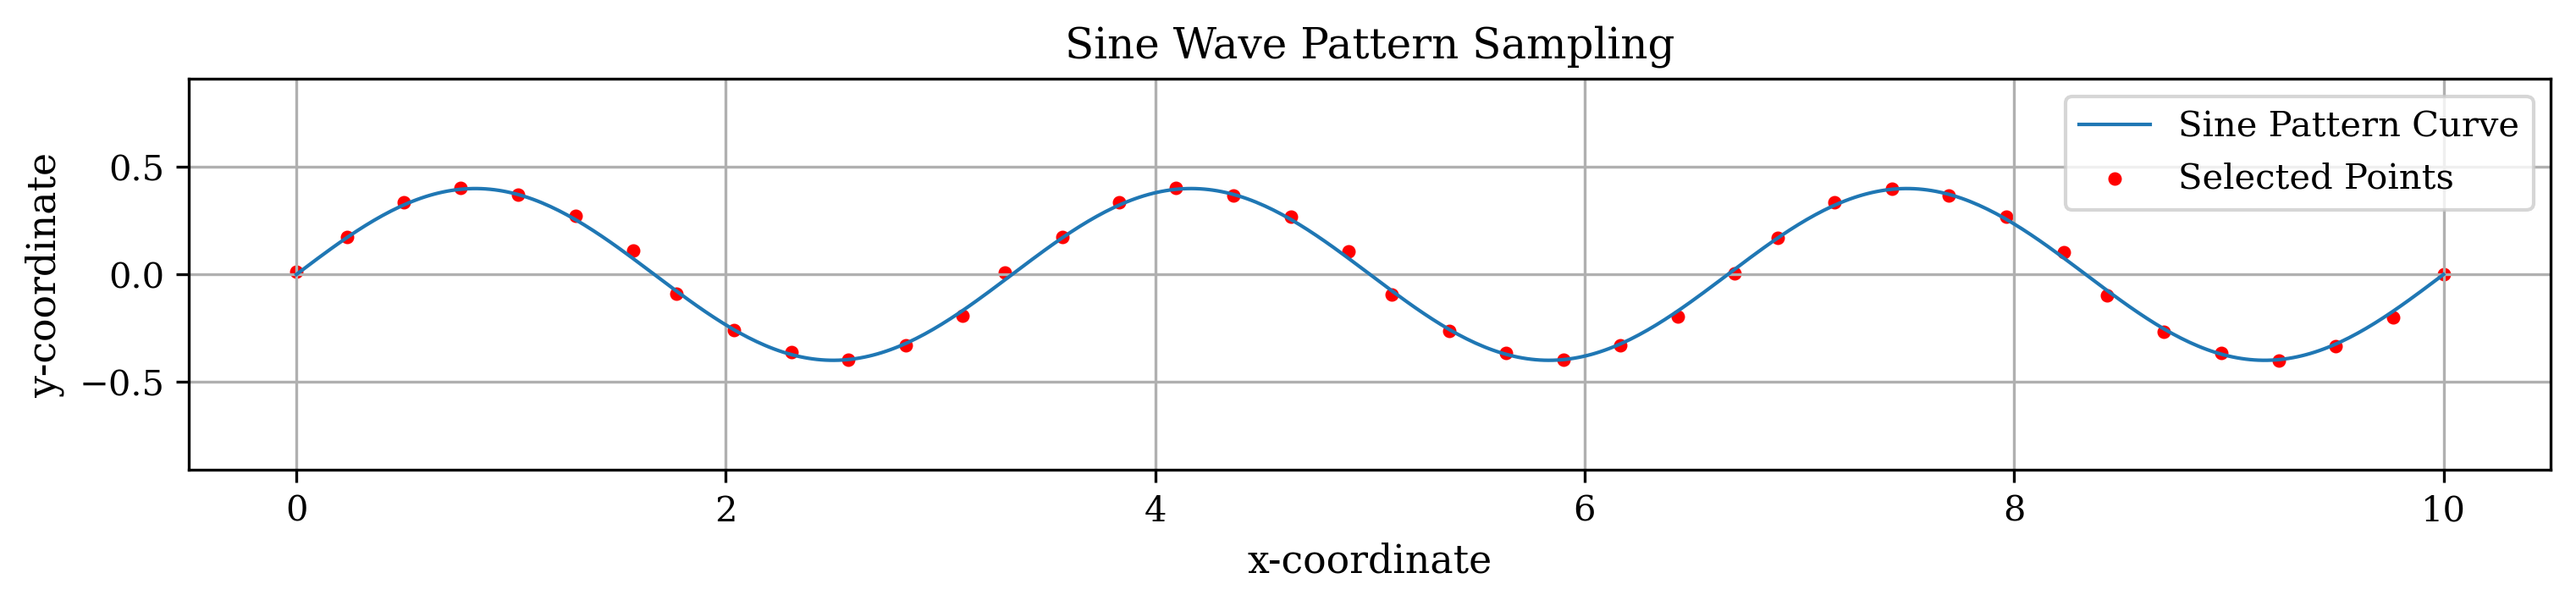

In [2]:
script_name = "ii-PINNs-inverse"
DIRS = setup_output_dirs(script_name)
torch.set_default_dtype(torch.float64) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
df = pd.read_csv("Input/data")
df.columns = df.columns.str.strip()

x_cfd = df["x-coordinate"].to_numpy()
y_cfd = df["y-coordinate"].to_numpy()
u_cfd = df["x-velocity"].to_numpy()
v_cfd = df["y-velocity"].to_numpy()

X_CFD = torch.from_numpy(
    np.column_stack((x_cfd, y_cfd))
).double()

indices, xy_sampled, u_sampled, v_sampled, (x_p, y_p), (xc, yc) = sine_wave_pattern_sampling(
    x_data=x_cfd,
    y_data=y_cfd,
    xy=X_CFD,
    u=u_cfd,
    v=v_cfd,
    n_samples=40,
    save_path=os.path.join(DIRS["plots"], "selected_points.png")
)

In [3]:
class Pinns:
    def __init__(self):
        # Device
        self.device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
        self.network = CNetwork().to(self.device)
        print("CUDA Available:", torch.cuda.is_available())

        # Physical parameters
        self.rho = 1000.0        # Density [kg/m³]
        self.eta_0 = 0.6491     # Zero-shear viscosity [Pa·s]
        self.eta_inf = 0.0016  # Infinite-shear viscosity [Pa·s]
        self.lam = 49.70         # Relaxation time [s]
        self.n_cy = 0.4303       # Power-law index
        self.a_cy = 1.9900      # Yasuda parameter

        # Geometry
        self.L = 10.0
        self.H = 1.0

        # Domain grid
        self.nx = 150
        self.ny = 30

        dx = self.L / self.nx
        dy = self.H / self.ny

        self.x = torch.arange(0, self.L + dx, dx)
        self.y = torch.arange(-self.H/2, self.H/2 + dy, dy)

        # interior collocation points
        X, Y = torch.meshgrid(self.x, self.y, indexing="ij")
        self.X = torch.stack((X.reshape(-1), Y.reshape(-1)), dim=1)
        self.X = self.X.to(self.device).requires_grad_(True)


        # Boundary points
        dx_b = self.L / 3500
        dy_b = self.H / 350

        self.x_b = torch.arange(0, self.L + dx_b, dx_b)
        self.y_b = torch.arange(-self.H/2, self.H/2 + dy_b, dy_b)

        # inlet (left boundary)
        y1 = self.y_b[len(self.y_b)//2:]
        Xin, Yin = torch.meshgrid(self.x_b[0:1], y1, indexing="ij")
        self.lw_inlet = torch.stack((Xin.reshape(-1), Yin.reshape(-1)), dim=1)

        # lower wall
        y2 = self.y_b[:len(self.y_b)//2]
        Xlw, Ylw = torch.meshgrid(self.x_b[0:1], y2, indexing="ij")
        self.lw_wall = torch.stack((Xlw.reshape(-1), Ylw.reshape(-1)), dim=1)

        # upper wall
        Xuw, Yuw = torch.meshgrid(self.x_b, self.y_b[-1:], indexing="ij")
        self.uw = torch.stack((Xuw.reshape(-1), Yuw.reshape(-1)), dim=1)

        # lower boundary
        Xdw, Ydw = torch.meshgrid(self.x_b, self.y_b[0:1], indexing="ij")
        self.dw = torch.stack((Xdw.reshape(-1), Ydw.reshape(-1)), dim=1)

        self.X_train = torch.cat([self.lw_wall, self.uw, self.dw], dim=0).to(self.device)
        
        # outlet (right boundary)
        Xout, Yout = torch.meshgrid(self.x_b[-1:], self.y_b, indexing="ij")
        self.X_train_p = torch.stack((Xout.reshape(-1), Yout.reshape(-1)), dim=1).to(self.device)

        # inverse
        # Boundary condition values
        # inlet parabolic profile
        # u_in = 0.5 * y1 * (0.5 - y1)
        # v_in = torch.zeros_like(u_in)
        # self.uv_lw_inlet = torch.stack((u_in, v_in), dim=1)

        # walls (no-slip)
        u_wall = torch.zeros_like(y2)
        v_wall = torch.zeros_like(y2)
        self.uv_lw_wall = torch.stack((u_wall, v_wall), dim=1)

        # upper wall
        u_uw = torch.zeros(len(self.x_b))
        v_uw = torch.zeros(len(self.x_b))
        self.uv_uw = torch.stack((u_uw, v_uw), dim=1)

        # lower boundary
        u_dw = torch.zeros(len(self.x_b))
        v_dw = torch.zeros(len(self.x_b))
        self.uv_dw = torch.stack((u_dw, v_dw), dim=1)

        self.uv_train = torch.cat(
            [self.uv_lw_wall, self.uv_uw, self.uv_dw],
            dim=0
        ).to(self.device)

        # outlet pressure
        self.p_train = torch.zeros(self.X_train_p.shape[0], device=self.device)

        # Data
        X_sample = xy_sampled.to(device).double().requires_grad_(True)
        u_sample = torch.from_numpy(u_sampled).to(device).double()
        v_sample = torch.from_numpy(v_sampled).to(device).double()
        self.X_data = X_sample.to(self.device)
        self.u_data = u_sample.to(self.device)
        self.v_data = v_sample.to(self.device)

        # Loss
        self.criterion = nn.MSELoss()

        # Optimizers
        self.adam = torch.optim.Adam(self.network.parameters(), lr=1e-4)

        self.optimizer = torch.optim.LBFGS(
            self.network.parameters(),
            lr=0.01,
            max_iter=2000,
            max_eval=2000,
            history_size=50,
            tolerance_grad=1e-8,
            tolerance_change=1.0 * np.finfo(float).eps,
            line_search_fn="strong_wolfe"
        )

        self.loss_history = []

    # gradient function
    def gradient(self, y, x, index):
        grad = torch.autograd.grad(
            y, x,
            grad_outputs=torch.ones_like(y),
            create_graph=True,
            retain_graph=True,
            only_inputs=True
        )[0]
        return grad[:, index]


    # Loss function
    def loss_f(self):
        # Boundary 
        uv_b = self.network(self.X_train)
        u_b = uv_b[:, 0]
        v_b = uv_b[:, 1]
        
        p_b = self.network(self.X_train_p)[:, 2]
        
        loss_u_b = self.criterion(u_b, self.uv_train[:, 0])
        loss_v_b = self.criterion(v_b, self.uv_train[:, 1])
        loss_p_b = self.criterion(p_b, self.p_train)
        loss_data = loss_u_b + loss_v_b +loss_p_b
    
        # Interior
        uvp = self.network(self.X)
        self.u_P = uvp[:, 0]
        self.v_P = uvp[:, 1]
        self.P_P = uvp[:, 2]
    
        # derivatives
        self.du_dx = self.gradient(self.u_P, self.X, 0)
        self.du_dy = self.gradient(self.u_P, self.X, 1)
        self.du_dxx = self.gradient(self.du_dx, self.X, 0)
        self.du_dyy = self.gradient(self.du_dy, self.X, 1)
    
        self.dv_dx = self.gradient(self.v_P, self.X, 0)
        self.dv_dy = self.gradient(self.v_P, self.X, 1)
        self.dv_dxx = self.gradient(self.dv_dx, self.X, 0)
        self.dv_dyy = self.gradient(self.dv_dy, self.X, 1)
    
        self.dp_dx = self.gradient(self.P_P, self.X, 0)
        self.dp_dy = self.gradient(self.P_P, self.X, 1)

        # Data loss (sampled CFD points)
        uv_data_pred = self.network(self.X_data)
        u_data_pred = uv_data_pred[:, 0]
        v_data_pred = uv_data_pred[:, 1]
        
        loss_u_data = self.criterion(u_data_pred, self.u_data)
        loss_v_data = self.criterion(v_data_pred, self.v_data)
        
        loss_data_samples = loss_u_data + loss_v_data

    
        # Navier-Stokes residuals
        gamma_dot = torch.sqrt(2*self.du_dx**2 + 2*self.dv_dy**2 + (self.du_dy + self.dv_dx)**2 + 1e-12)
        mu = self.eta_inf + (self.eta_0 - self.eta_inf) * \
             (1 + (self.lam * gamma_dot)**self.a_cy)**((self.n_cy - 1)/self.a_cy)
        # stress components
        tau_xx = 2*mu*self.du_dx
        tau_xy = mu*(self.du_dy + self.dv_dx)
        tau_yy = 2*mu*self.dv_dy
        
        # divergence of stress
        dtau_xx_dx = self.gradient(tau_xx, self.X, 0)
        dtau_xy_dy = self.gradient(tau_xy, self.X, 1)
        dtau_xy_dx = self.gradient(tau_xy, self.X, 0)
        dtau_yy_dy = self.gradient(tau_yy, self.X, 1)

        # Navier-Stokes equations residuals
        continuity = self.du_dx + self.dv_dy
        momentum_x = self.rho * (self.u_P * self.du_dx + self.v_P * self.du_dy) \
             + self.dp_dx \
             - (dtau_xx_dx + dtau_xy_dy)
        momentum_y = self.rho * (self.u_P * self.dv_dx + self.v_P * self.dv_dy) \
             + self.dp_dy \
             - (dtau_xy_dx + dtau_yy_dy)
    
        loss_continuity = self.criterion(continuity, torch.zeros_like(continuity))
        loss_momentum_x = self.criterion(momentum_x, torch.zeros_like(momentum_x))
        loss_momentum_y = self.criterion(momentum_y, torch.zeros_like(momentum_y))
    
        loss_pde = loss_continuity + loss_momentum_x + loss_momentum_y
        loss_total = loss_data + loss_pde + 10 * loss_data_samples
    
        return loss_total, loss_data, loss_continuity, loss_momentum_x, loss_momentum_y
    
    # Training loop
    def train(self, num_epochs=5000):
        self.network.train()
        run_number    = get_next_run_number(script_name)
        model_path    = os.path.join(DIRS["models"],  "model_best.pth")
        history_path  = os.path.join(DIRS["history"], f"loss_history_run{run_number:03d}.csv")
        time_path = os.path.join(DIRS["history"], f"adam_epoch_time_run{run_number:03d}.csv")
        print(f"Run {run_number:03d}")
        print(f"   Model   -> {model_path}  (overwrites previous)")
        print(f"   History -> {history_path}")
        epoch_times = []
        checkpoint_path = "pinns_checkpoint.pth"
    
        for i in range(num_epochs):
            start_time = time.time()
            self.adam.zero_grad()
            loss_total, loss_data, loss_continuity, loss_momentum_x, loss_momentum_y = self.loss_f()
            loss_total.backward()
            self.adam.step()
    
            self.loss_history.append({"epoch": i, "loss_total": loss_total.item()})
            epoch_duration = time.time() - start_time
            epoch_times.append({"epoch": i, "duration": epoch_duration})    
            if i % 10 == 0:
                print(f"Epoch {i}: Total Loss={loss_total.item():.3e}, "
                      f"Boundary Loss={loss_data.item():.3e}, "
                      f"Continuity Loss={loss_continuity.item():.3e}, "
                      f"Momentum X Loss={loss_momentum_x.item():.3e}, "
                      f"Momentum Y Loss={loss_momentum_y.item():.3e}")
            if i % 100 == 0:
                torch.save(self.network.state_dict(), model_path)
                print(f"  Checkpoint saved -> {model_path}")
                
        df_time = pd.DataFrame(epoch_times)
        df_time.to_csv(time_path, index=False)
        print(f"Adam epoch times saved -> {time_path}")
                
        # LBFGS phase
        lbfgs_step = [0]
        adam_epochs  = num_epochs
        def closure():
            self.optimizer.zero_grad()
            loss_total, loss_data, loss_continuity, loss_momentum_x, loss_momentum_y = self.loss_f()
            loss_total.backward()
            lbfgs_step[0] += 1

            self.loss_history.append({
                "epoch": adam_epochs + lbfgs_step[0],
                "loss_total": loss_total.item()
            })
            
            print(f"[LBFGS step {lbfgs_step[0]}] Loss: Total={loss_total.item():.3e}, "
                  f"Boundary={loss_data.item():.3e}, "
                  f"Continuity={loss_continuity.item():.3e}, "
                  f"Momentum X={loss_momentum_x.item():.3e}, "
                  f"Momentum Y={loss_momentum_y.item():.3e}")
            return loss_total
        self.optimizer.step(closure)
        print("Starting LBFGS...")
        torch.save(self.network.state_dict(), model_path)
        print(f"Final model saved -> {model_path}")
        df_run = pd.DataFrame(self.loss_history)
        df_run.to_csv(history_path, index=False)
        print(f"Run history saved -> {history_path}")

    def plot(self, nx_plot=300, ny_plot=100):
        self.network.eval()
    

        # 1. Regular grid for PINN predictions

        x_plot = torch.linspace(0, self.L, nx_plot, device=self.device)
        y_plot = torch.linspace(-self.H/2, self.H/2, ny_plot, device=self.device)
        Xg, Yg = torch.meshgrid(x_plot, y_plot, indexing='ij')
        xy_grid = torch.stack([Xg.flatten(), Yg.flatten()], dim=1).double()
    
        with torch.no_grad():
            uvp_pred = self.network(xy_grid)
            u_pred = uvp_pred[:, 0]
            v_pred = uvp_pred[:, 1]
            p_pred = uvp_pred[:, 2]
    
        # Move to CPU for plotting
        u_grid = u_pred.detach().cpu().reshape(nx_plot, ny_plot)
        v_grid = v_pred.detach().cpu().reshape(nx_plot, ny_plot)
        p_grid = p_pred.detach().cpu().reshape(nx_plot, ny_plot)
    
        X_np = Xg.cpu().numpy()
        Y_np = Yg.cpu().numpy()
    

        # 2. Compute viscosity from PINN on the regular grid

        xy_grid = xy_grid.clone().detach().requires_grad_(True)
        uvp = self.network(xy_grid)
        u = uvp[:, 0]
        v = uvp[:, 1]
        p = uvp[:, 2]
        du_dx = self.gradient(u, xy_grid, 0)
        du_dy = self.gradient(u, xy_grid, 1)
        dv_dx = self.gradient(v, xy_grid, 0)
        dv_dy = self.gradient(v, xy_grid, 1)
        gamma_dot = torch.sqrt(2*du_dx**2 + 2*dv_dy**2 + (du_dy + dv_dx)**2 + 1e-12)
        eta_pinn = self.eta_inf + (self.eta_0 - self.eta_inf) * \
             (1 + (self.lam * gamma_dot)**self.a_cy)**((self.n_cy - 1)/self.a_cy)
        eta_grid = eta_pinn.detach().cpu().reshape(nx_plot, ny_plot)
    

        # 3. Load CFD reference data

        df = pd.read_csv("Input/data")
        df.columns = df.columns.str.strip()
    
        x_cfd = df["x-coordinate"].values
        y_cfd = df["y-coordinate"].values
        u_cfd = df["x-velocity"].values
        v_cfd = df["y-velocity"].values
        p_cfd = df["pressure"].values
        viscosity_cfd = df["viscosity-lam"].values
    
        # PINN predictions at exact CFD points
        
        xy_cfd_torch = torch.from_numpy(np.column_stack((x_cfd, y_cfd))).to(self.device).double()
        with torch.no_grad():
            uvp_pinn_cfd = self.network(xy_cfd_torch)
            u_pinn_cfd = uvp_pinn_cfd[:, 0].detach().cpu()
            v_pinn_cfd = uvp_pinn_cfd[:, 1].detach().cpu()
            p_pinn_cfd = uvp_pinn_cfd[:, 2].detach().cpu()
    
        # Viscosity from PINN at CFD points
        
        xy_cfd_torch.requires_grad_(True)
        uvp_pp = self.network(xy_cfd_torch)
        u_pp = uvp_pp[:, 0]
        v_pp = uvp_pp[:, 1]
        p_pp = uvp_pp[:, 2]
        du_dx_pp = self.gradient(u_pp, xy_cfd_torch, 0)
        du_dy_pp = self.gradient(u_pp, xy_cfd_torch, 1)
        dv_dx_pp = self.gradient(v_pp, xy_cfd_torch, 0)
        dv_dy_pp = self.gradient(v_pp, xy_cfd_torch, 1)
        gamma_dot_pp = torch.sqrt(2*du_dx_pp**2 + 2*dv_dy_pp**2 + (du_dy_pp + dv_dx_pp)**2 + 1e-12)
        eta_pinn_cfd = self.eta_inf + (self.eta_0 - self.eta_inf) * \
             (1 + (self.lam * gamma_dot_pp)**self.a_cy)**((self.n_cy - 1)/self.a_cy)
        eta_pinn_cfd = eta_pinn_cfd.detach().cpu().numpy().flatten()
    

        # 4. Interpolate CFD data onto regular grid

        u_cfd_grid = griddata((x_cfd, y_cfd), u_cfd, (X_np, Y_np), method='linear', fill_value=np.nan)
        v_cfd_grid = griddata((x_cfd, y_cfd), v_cfd, (X_np, Y_np), method='linear', fill_value=np.nan)
        p_cfd_grid = griddata((x_cfd, y_cfd), p_cfd, (X_np, Y_np), method='linear', fill_value=np.nan)
        eta_cfd_grid = griddata((x_cfd, y_cfd), viscosity_cfd, (X_np, Y_np), method='linear', fill_value=np.nan)
    

        # 5. Compute relative errors

        eps = 1e-12
        u_range = u_cfd.max() - u_cfd.min() + eps
        v_range = np.abs(v_cfd).max() + eps
        p_range = p_cfd.max() - p_cfd.min() + eps
        eta_range = viscosity_cfd.max() - viscosity_cfd.min() + eps
    
        rel_err_u = 100.0 * np.abs(u_pinn_cfd.numpy() - u_cfd) / u_range
        rel_err_v = 100.0 * np.abs(v_pinn_cfd.numpy() - v_cfd) / v_range
        rel_err_p = 100.0 * np.abs((p_pinn_cfd.numpy() - p_pinn_cfd.min().numpy()) - (p_cfd - p_cfd.min())) / p_range
    

        # 5b. Compute L2 errors

        def compute_l2_error(pred, ref):
            return 100.0 * np.linalg.norm(pred - ref) / (np.linalg.norm(ref) + 1e-12)
    
        l2_u = compute_l2_error(u_pinn_cfd.numpy(), u_cfd)
        l2_v = compute_l2_error(v_pinn_cfd.numpy(), v_cfd)
        l2_p = compute_l2_error(p_pinn_cfd.numpy() - p_pinn_cfd.min().numpy(), p_cfd - p_cfd.min())
    

        # 6. Plotting helper functions

        def contour_plot(data, title, fname, label, cmap="jet"):
            fpath = os.path.join(DIRS["plots"], fname)
            plt.figure(figsize=(12, 3))
            cf = plt.contourf(X_np, Y_np, data, levels=80, cmap=cmap)
            plt.colorbar(cf, label=label)
            plt.xlabel("x [m]")
            plt.ylabel("y [m]")
            plt.title(title)
            plt.tight_layout()
            plt.savefig(fpath, dpi=300, bbox_inches='tight')
            plt.show()
            plt.close()
    
        def tricontour_plot(x, y, values, title, fname, label, cmap="jet"):
            fpath = os.path.join(DIRS["plots"], fname)
            plt.figure(figsize=(12, 3))
            cf = plt.tricontourf(x, y, values, levels=80, cmap=cmap)
            plt.colorbar(cf, label=label)
            plt.xlabel("x [m]")
            plt.ylabel("y [m]")
            plt.title(title)
            plt.tight_layout()
            plt.savefig(fpath, dpi=300, bbox_inches='tight')
            plt.show()
            plt.close()
    

        # 7. PINN predicted fields (with L2)

        contour_plot(u_grid.numpy(), f"PINN: x-velocity (u)", "u_pinn.png", "u [m/s]")
        contour_plot(v_grid.numpy(), f"PINN: y-velocity (v)", "v_pinn.png", "v [m/s]")
        contour_plot(p_grid.numpy(), f"PINN: Pressure (p)", "p_pinn.png", "p [Pa]")
        contour_plot(eta_grid.numpy(), f"PINN: Viscosity (η)", "viscosity_pinn.png", "η [Pa·s]")
    

        # 8. CFD reference fields (interpolated)

        contour_plot(u_cfd_grid, f"CFD Reference: x-velocity (u)", "u_cfd.png", "u [m/s]")
        contour_plot(v_cfd_grid, f"CFD Reference: y-velocity (v)", "v_cfd.png", "v [m/s]")
        contour_plot(p_cfd_grid, f"CFD Reference: Pressure (p)", "p_cfd.png", "p [Pa]")
        contour_plot(eta_cfd_grid, f"CFD Reference: Viscosity (η)", "viscosity_cfd.png", "η [Pa·s]")
    

        # 9. Relative error plots (with L2)

        tricontour_plot(x_cfd, y_cfd, rel_err_u, f"Relative Error in u-velocity (%)\nL2={l2_u:.2f}%", "error_u_rel.png", "Error [%]", cmap="viridis")
        tricontour_plot(x_cfd, y_cfd, rel_err_v, f"Relative Error in v-velocity (%)\nL2={l2_v:.2f}%", "error_v_rel.png", "Error [%]", cmap="viridis")
        tricontour_plot(x_cfd, y_cfd, rel_err_p, f"Relative Error in Pressure (%)\nL2={l2_p:.2f}%", "error_p_rel.png", "Error [%]", cmap="viridis")
    

        # 10. Velocity profile at inlet (x = 0)

        ny_prof = 200
        y_prof = torch.linspace(0, self.H/2, ny_prof, device=self.device).double()
        x_prof = torch.zeros_like(y_prof)
        xy_inlet = torch.stack([x_prof, y_prof], dim=1)
    
        with torch.no_grad():
            uvp_pinn_in = self.network(xy_inlet)
            u_pinn_in = uvp_pinn_in[:, 0]
            v_pinn_in = uvp_pinn_in[:, 1]
            p_pinn_in = uvp_pinn_in[:, 2]
    
        y_np = y_prof.cpu().numpy()
        u_pinn_np = u_pinn_in.detach().cpu().numpy().flatten()
        u_target = 0.5 * y_np * (0.5 - y_np)
        fpath = os.path.join(DIRS["plots"], "u_profile_x0.png")
    
        plt.figure(figsize=(4, 6))
        plt.plot(u_pinn_np, y_np, 'r-', lw=2, label='PINN')
        plt.plot(u_target, y_np, 'k--', lw=2, label='Inlet profile')
        plt.xlabel('u [m/s]')
        plt.ylabel('y [m]')
        plt.title('Velocity profile at x = 0')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(fpath, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

CUDA Available: True
Run 001
   Model   -> ii-PINNs-inverse-Results/models/model_best.pth  (overwrites previous)
   History -> ii-PINNs-inverse-Results/history/loss_history_run001.csv
Epoch 0: Total Loss=3.688e+00, Boundary Loss=1.490e-01, Continuity Loss=1.025e-03, Momentum X Loss=1.445e-03, Momentum Y Loss=3.353e-03
  Checkpoint saved -> ii-PINNs-inverse-Results/models/model_best.pth
Epoch 10: Total Loss=2.265e+00, Boundary Loss=1.583e-01, Continuity Loss=3.211e-03, Momentum X Loss=8.984e-04, Momentum Y Loss=3.109e-03
Epoch 20: Total Loss=1.513e+00, Boundary Loss=2.072e-01, Continuity Loss=5.974e-03, Momentum X Loss=3.533e-04, Momentum Y Loss=2.811e-03
Epoch 30: Total Loss=1.248e+00, Boundary Loss=2.589e-01, Continuity Loss=8.255e-03, Momentum X Loss=9.277e-05, Momentum Y Loss=2.413e-03
Epoch 40: Total Loss=1.181e+00, Boundary Loss=2.791e-01, Continuity Loss=9.059e-03, Momentum X Loss=2.070e-04, Momentum Y Loss=1.923e-03
Epoch 50: Total Loss=1.134e+00, Boundary Loss=2.656e-01, Contin

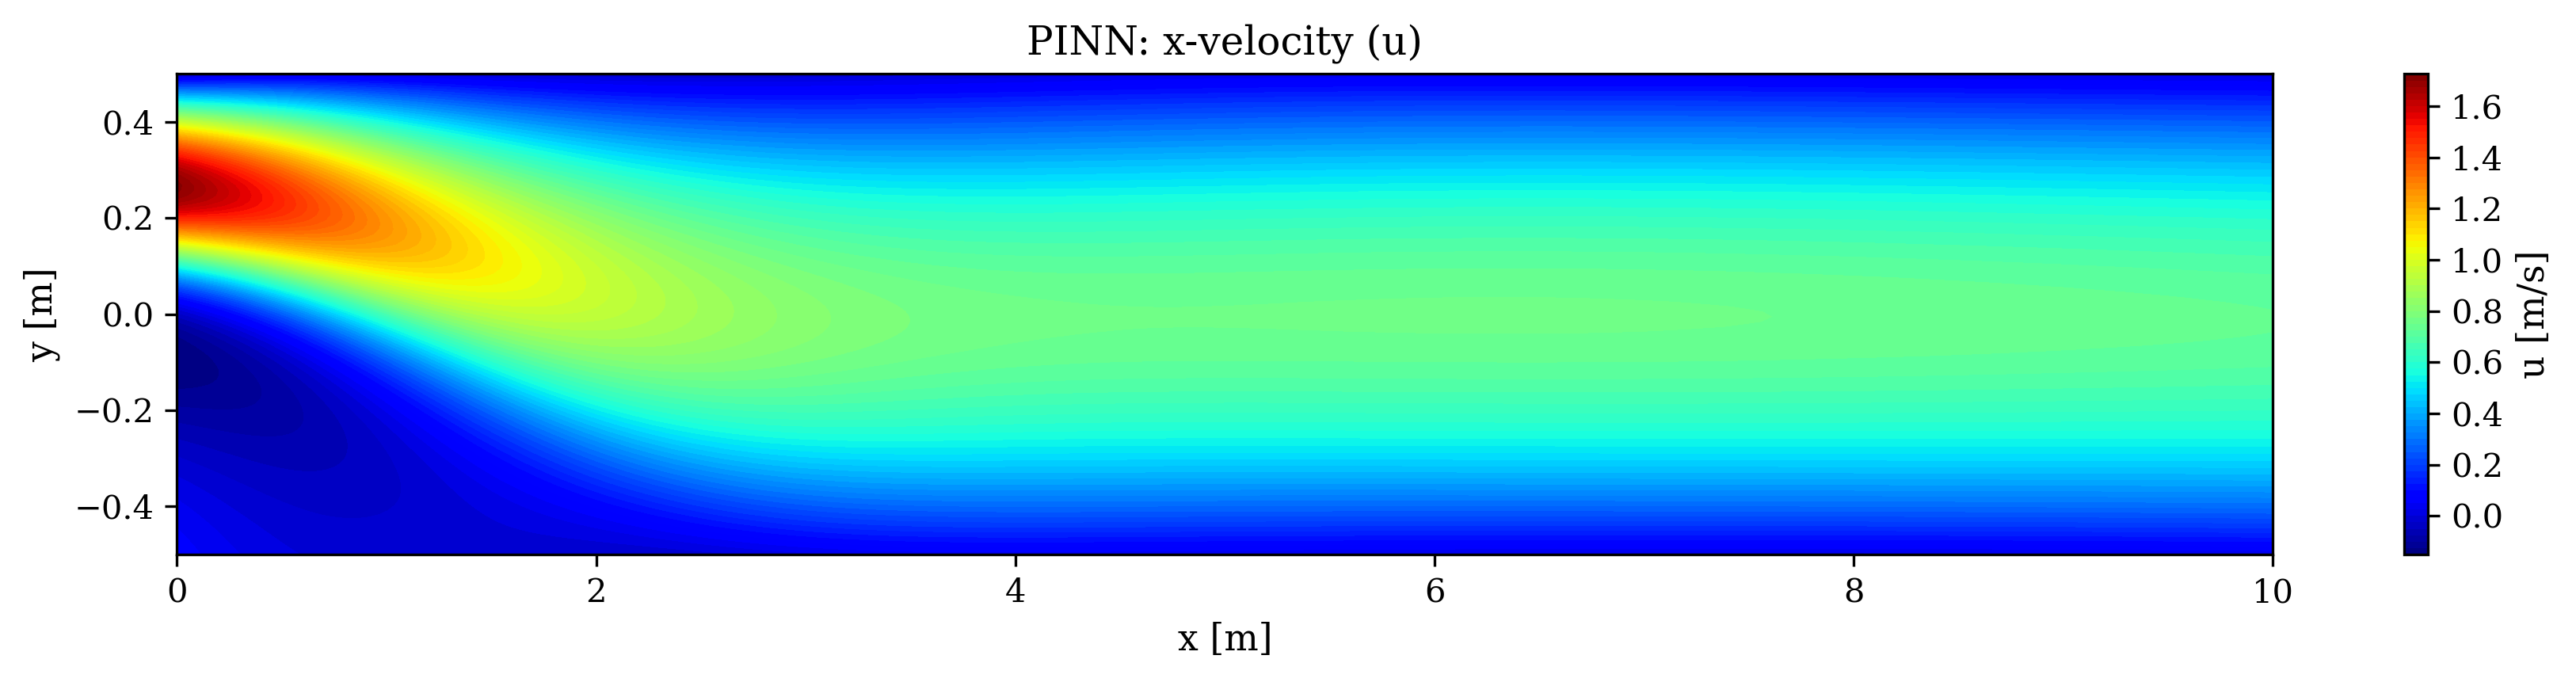

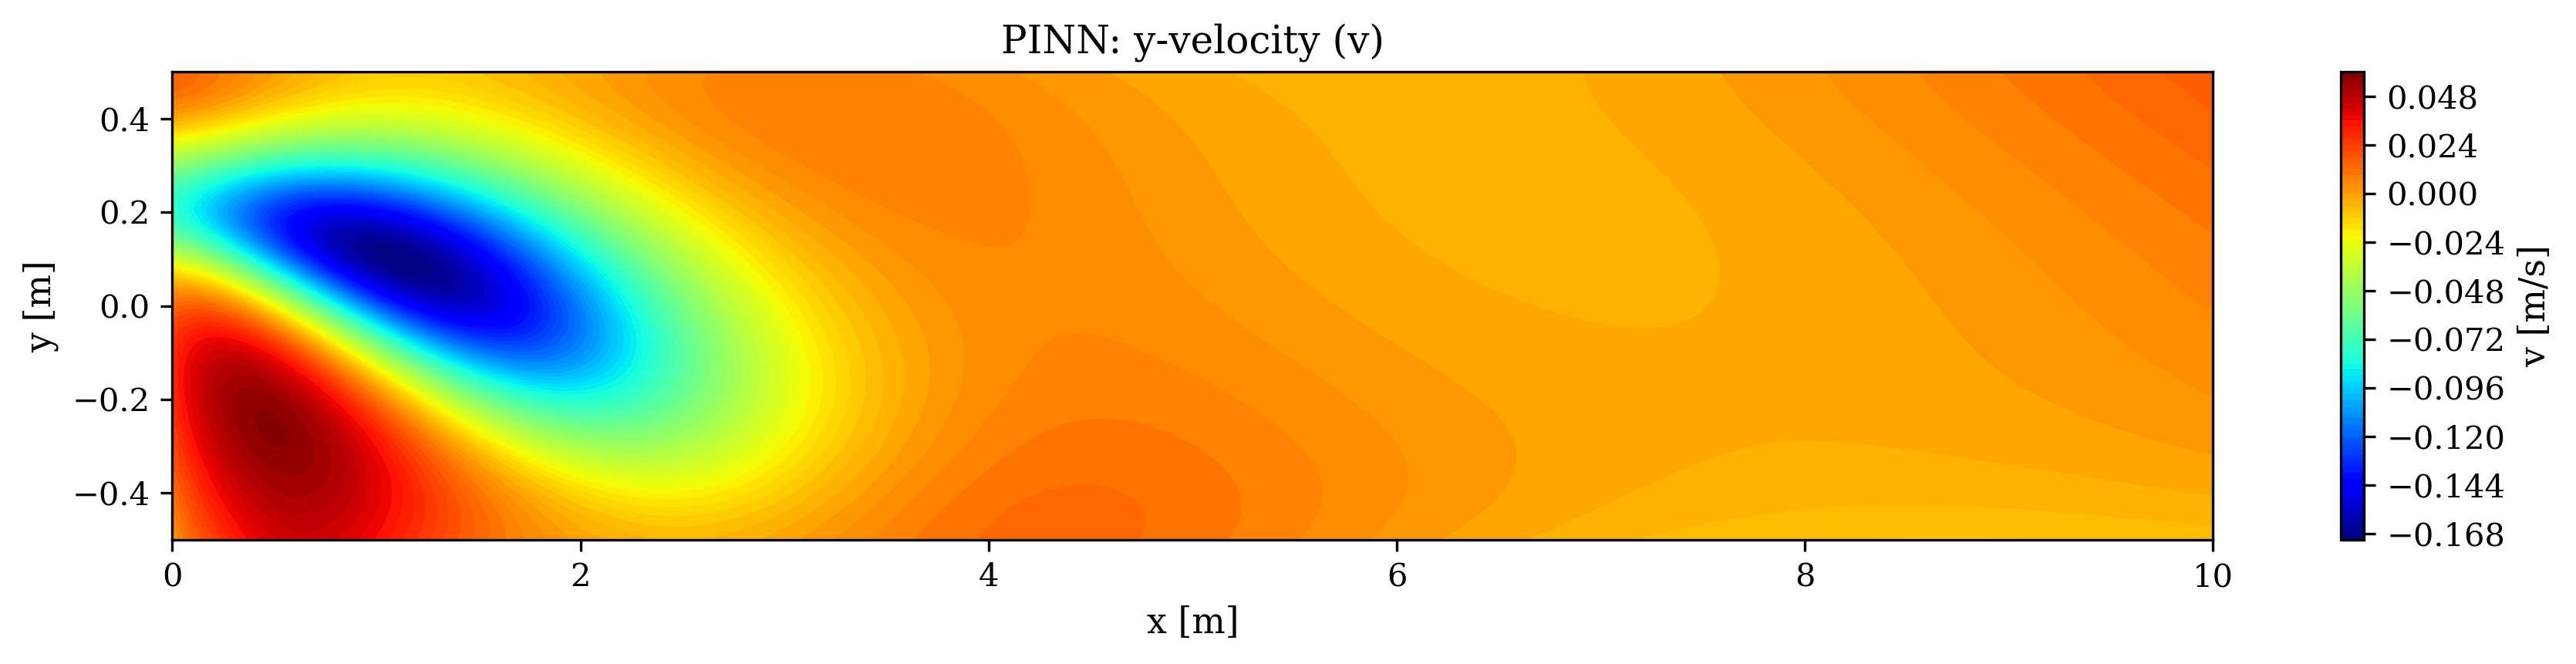

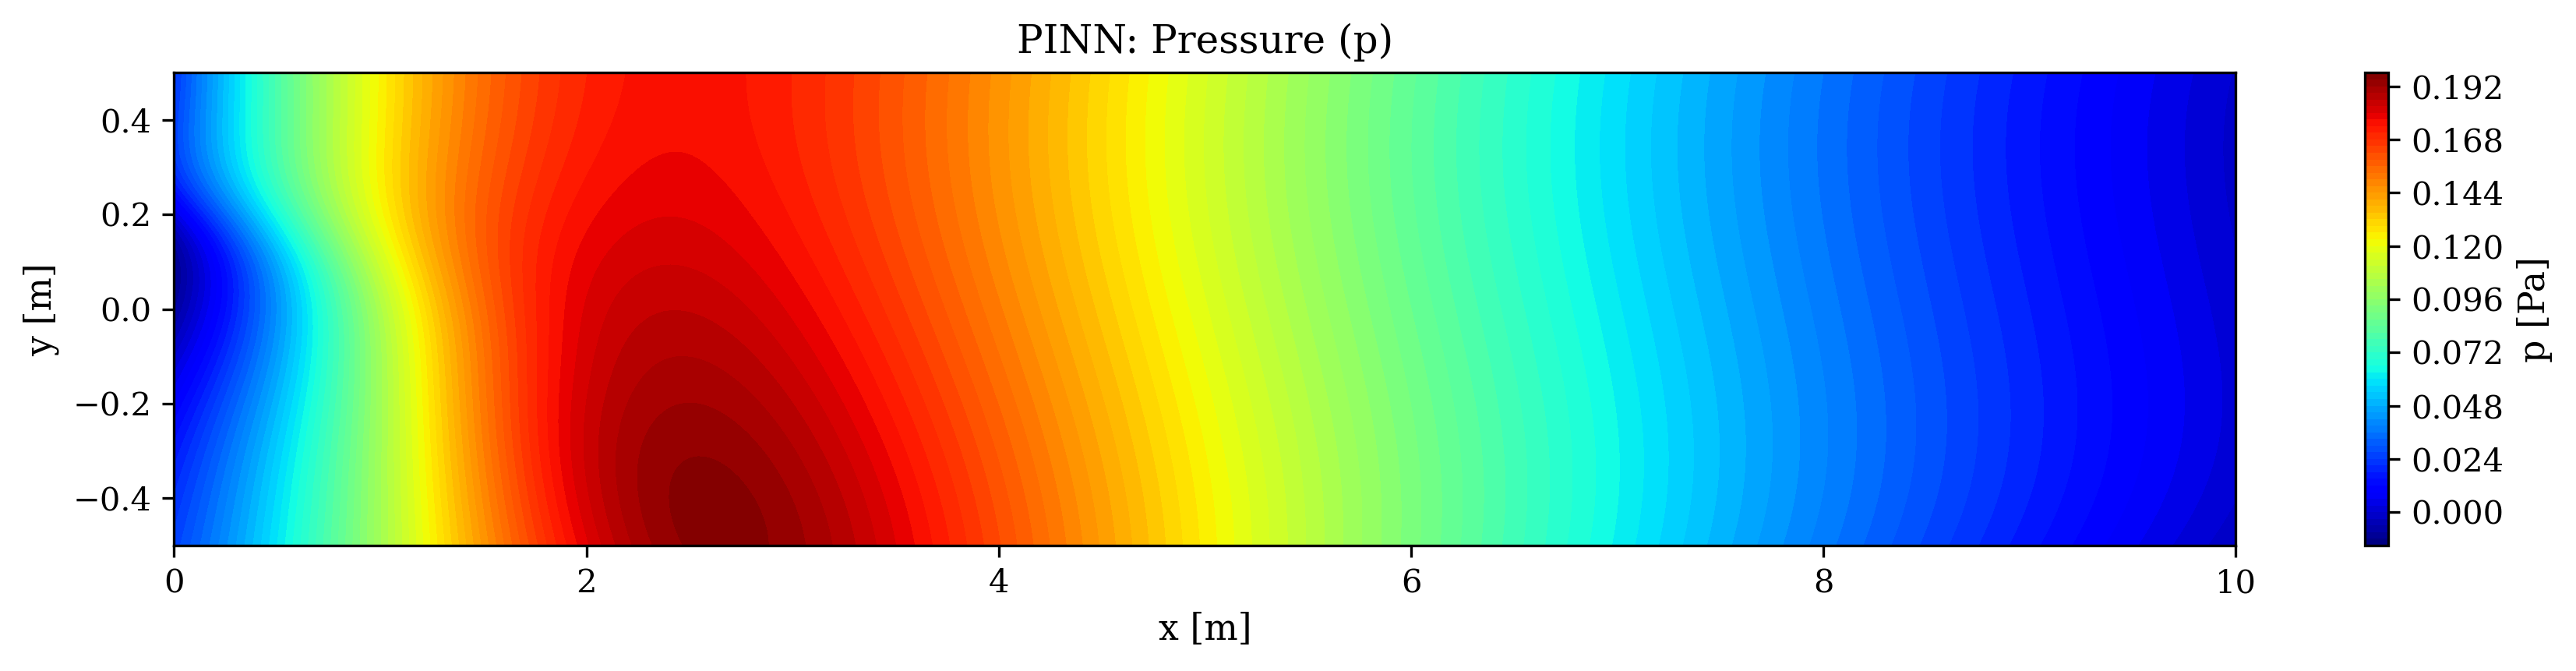

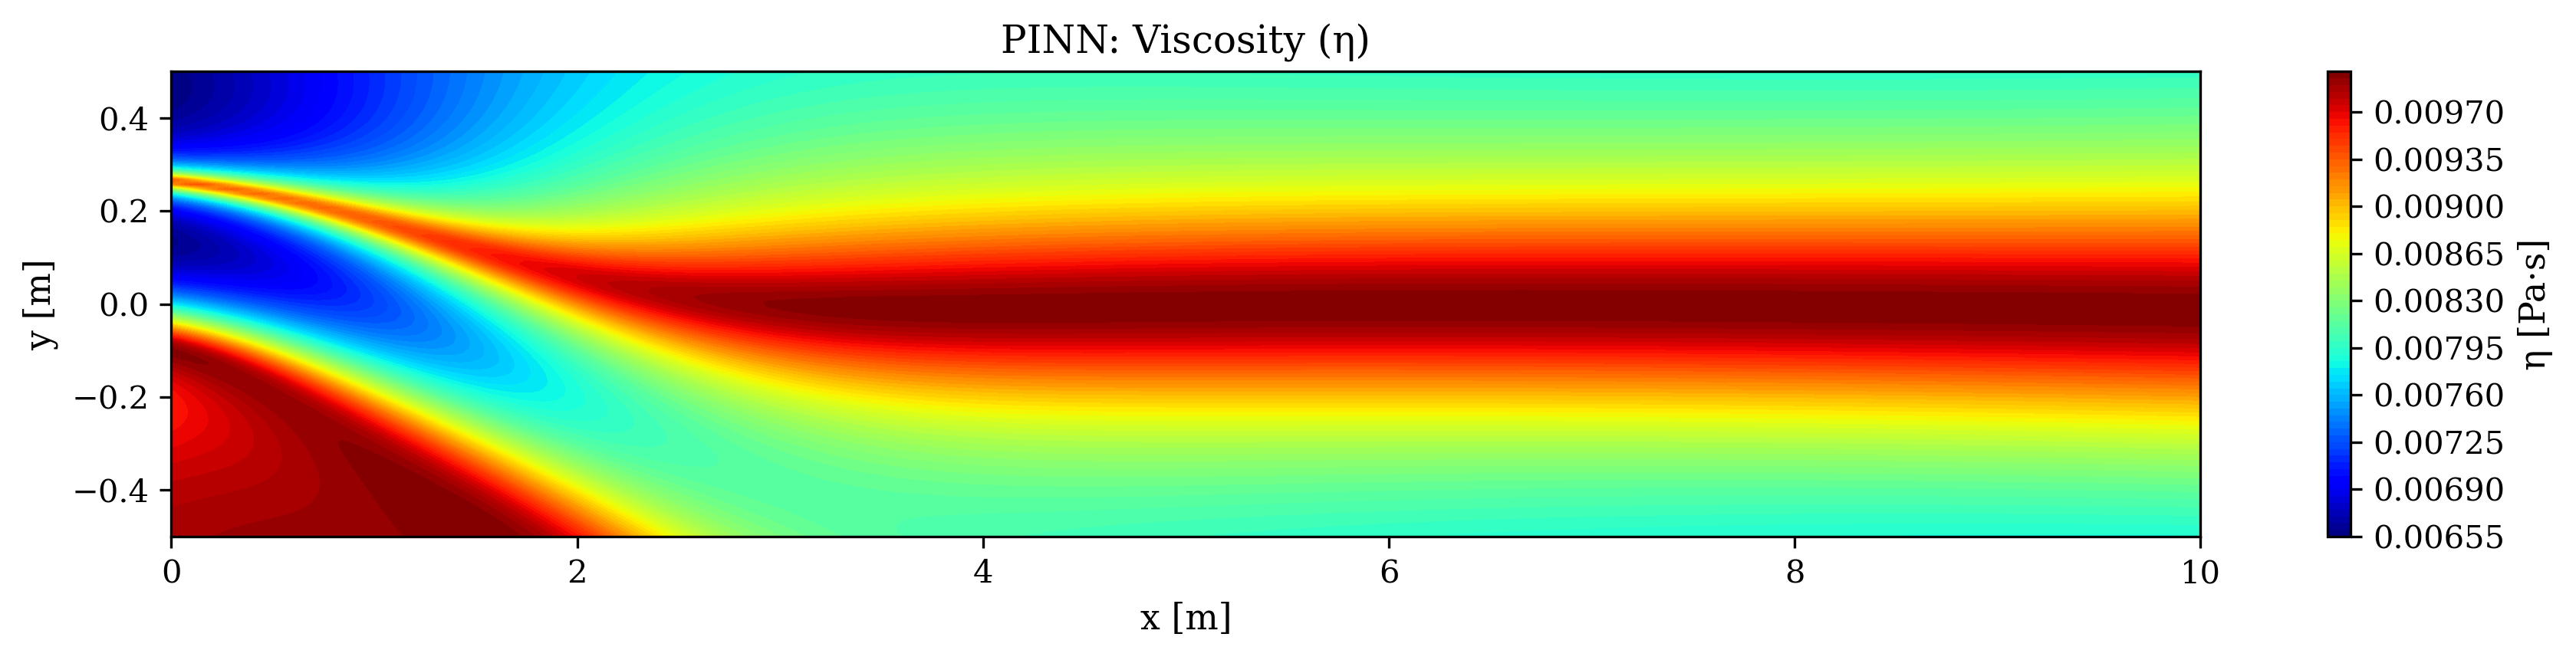

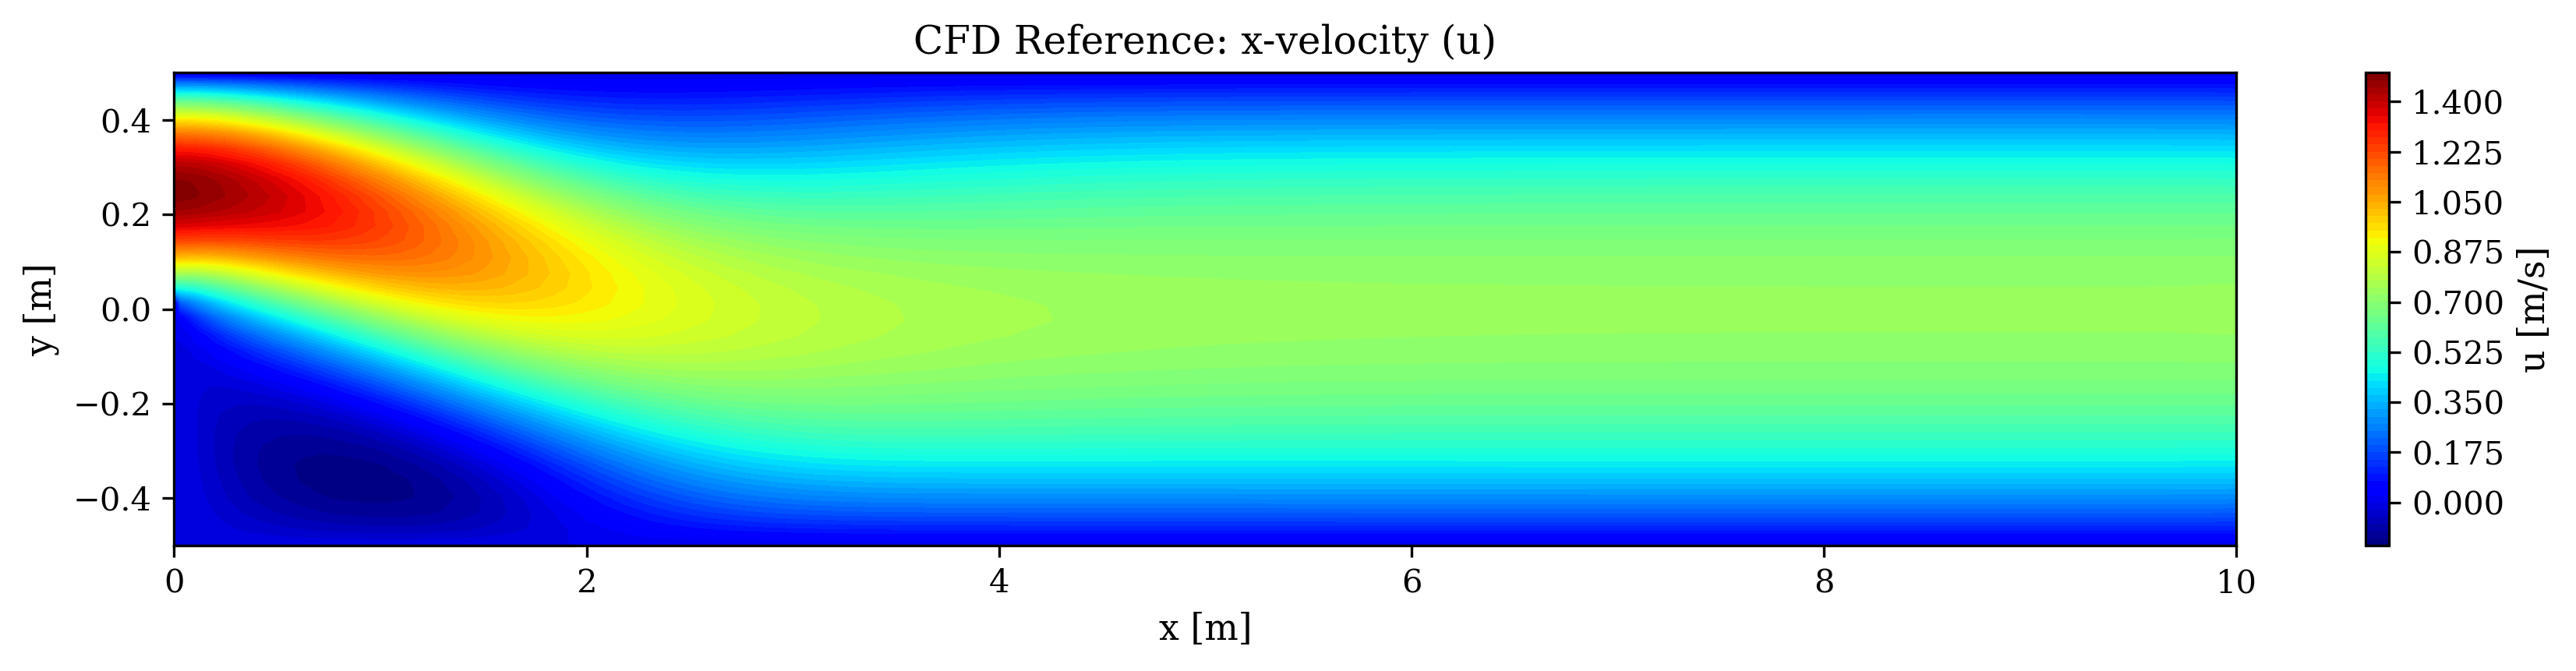

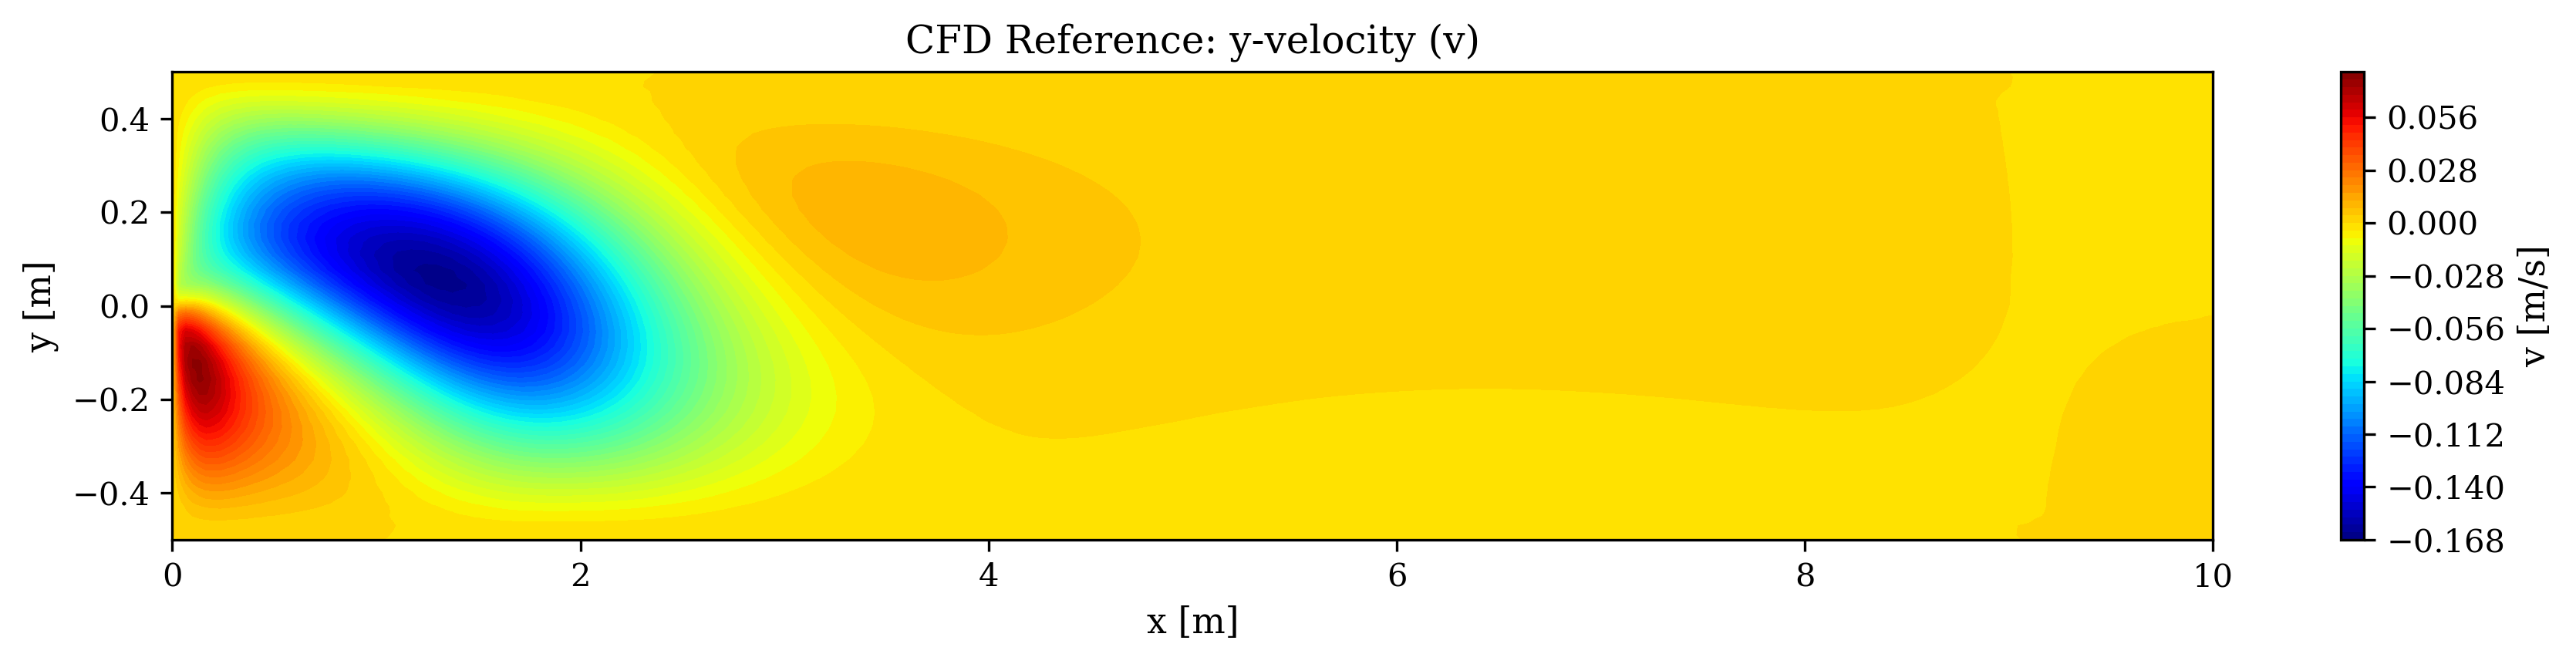

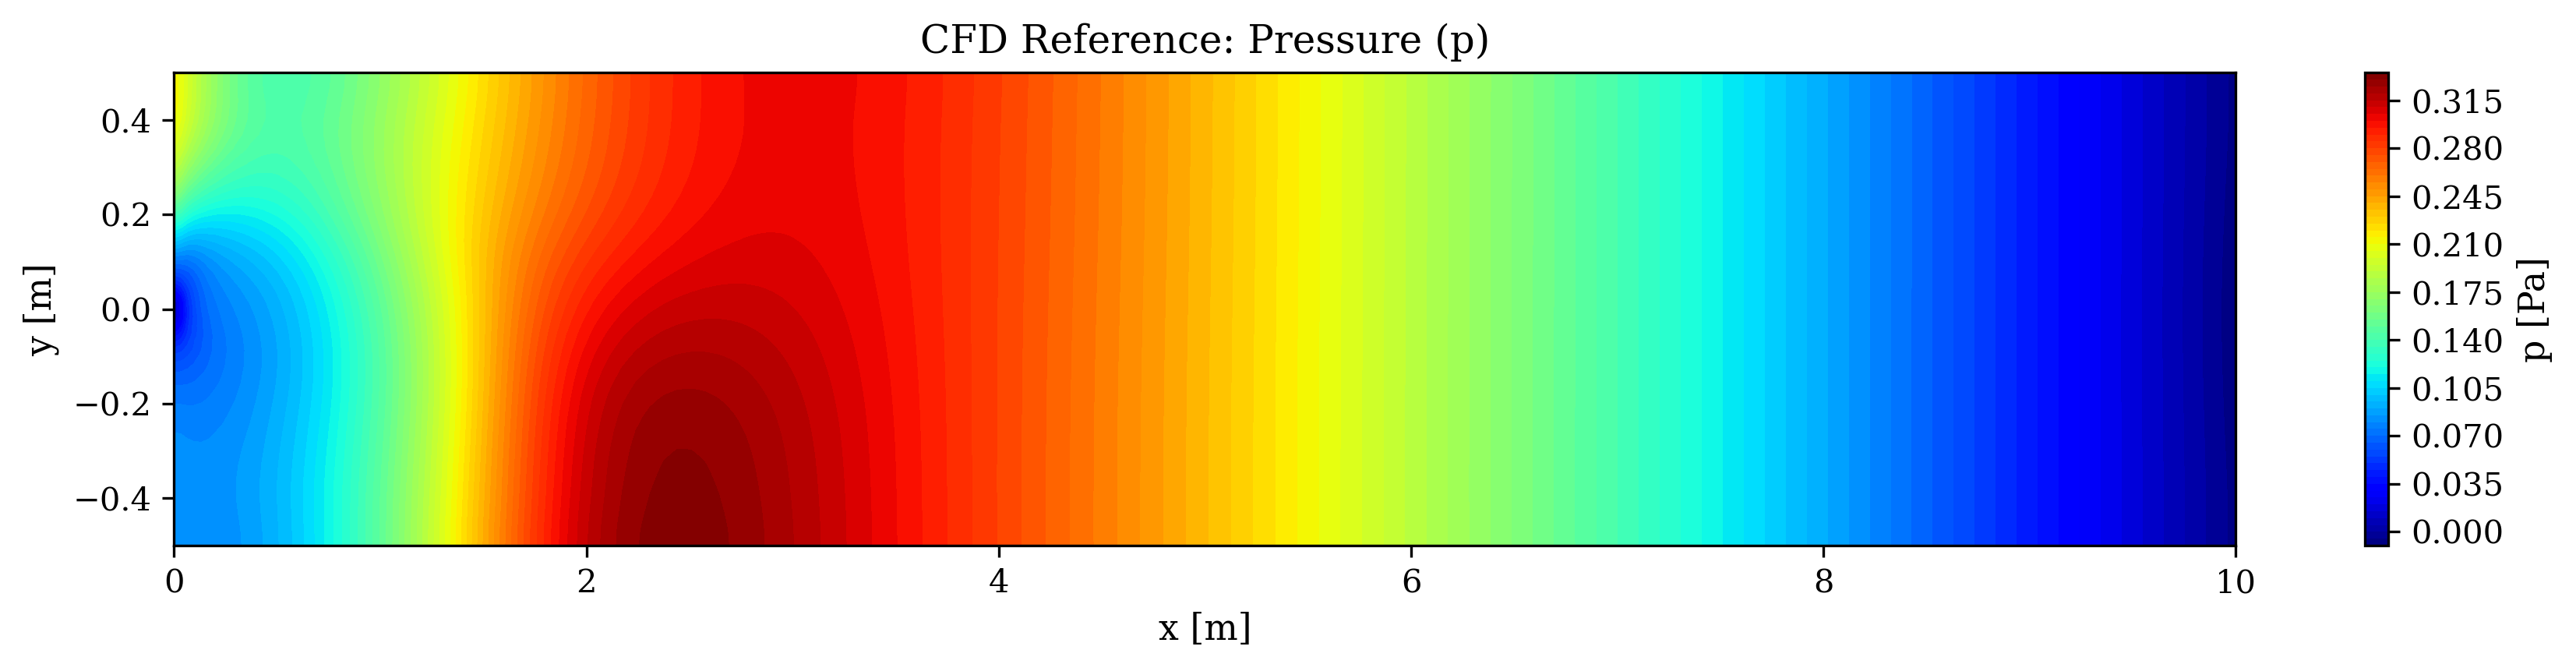

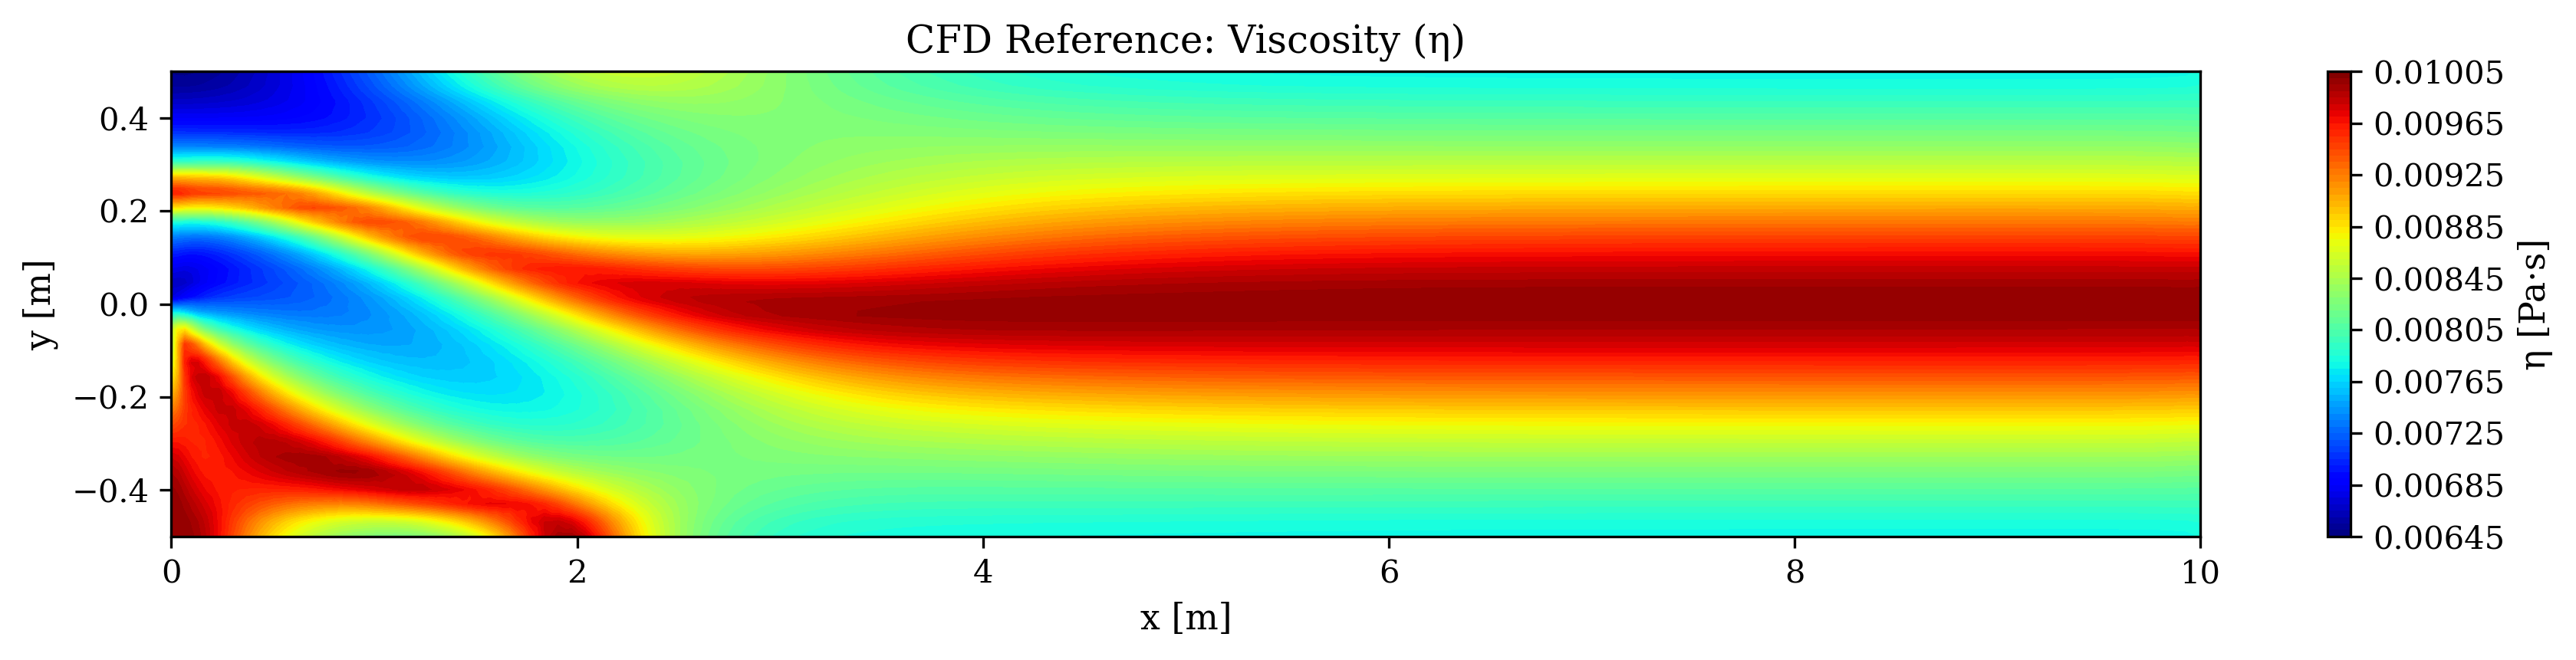

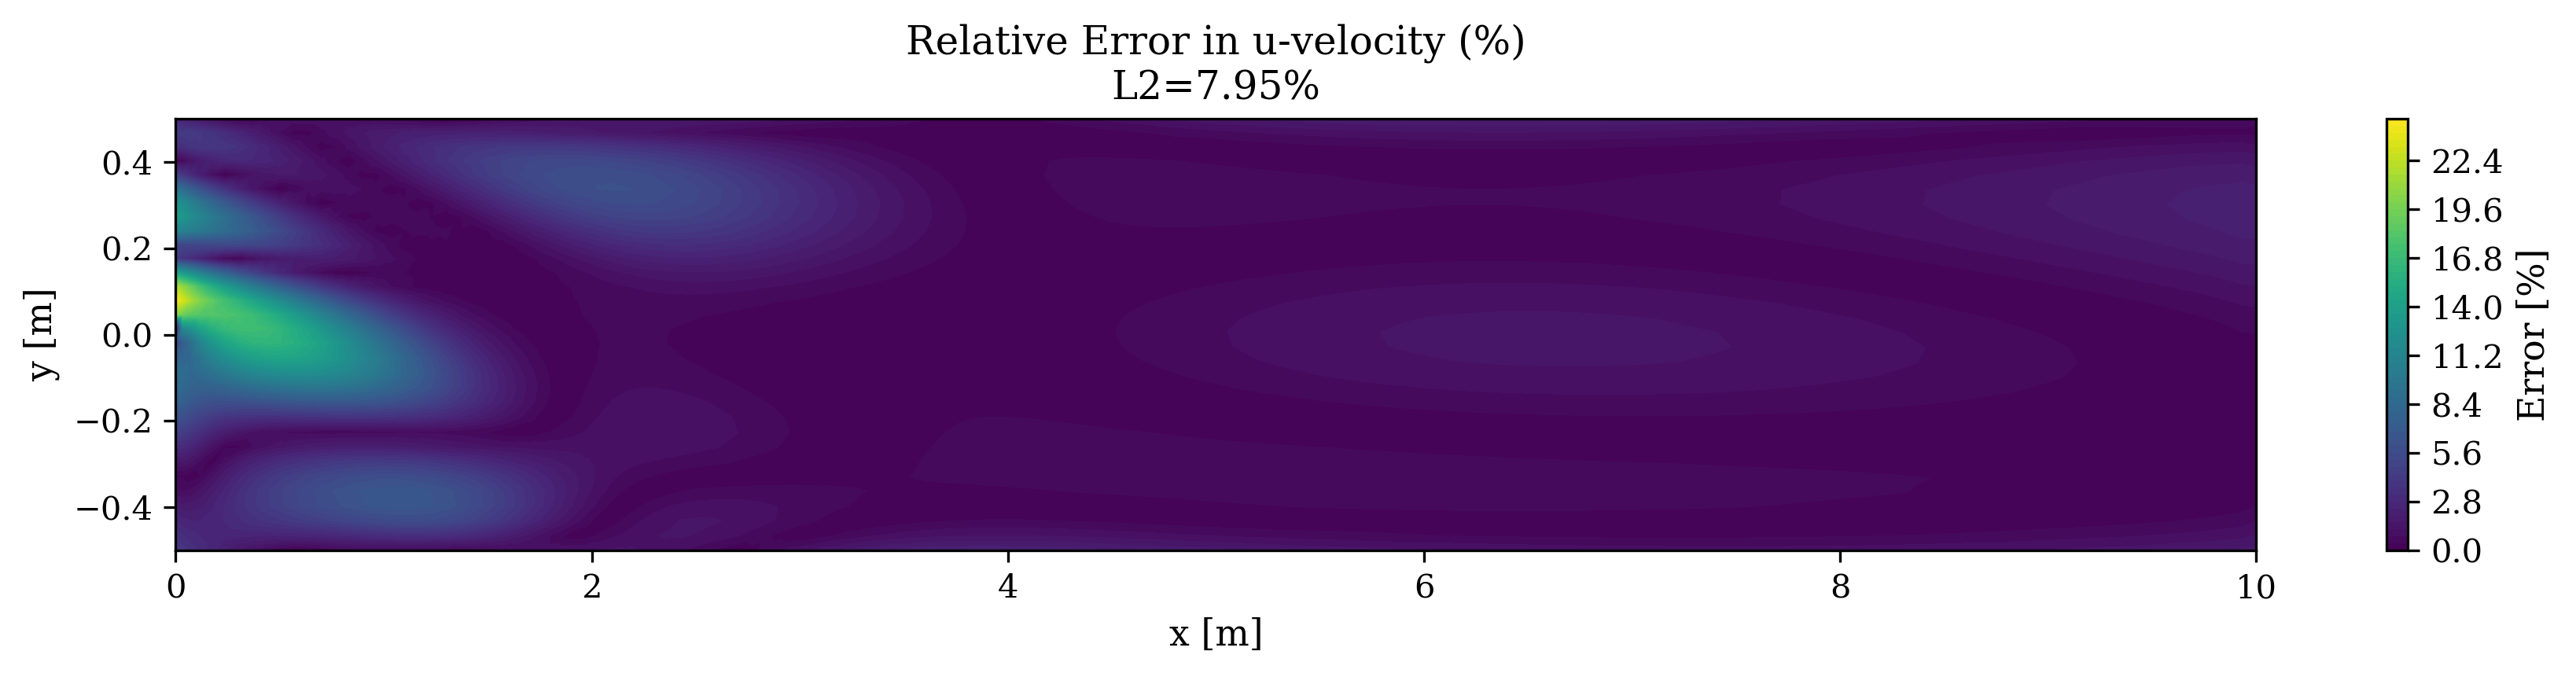

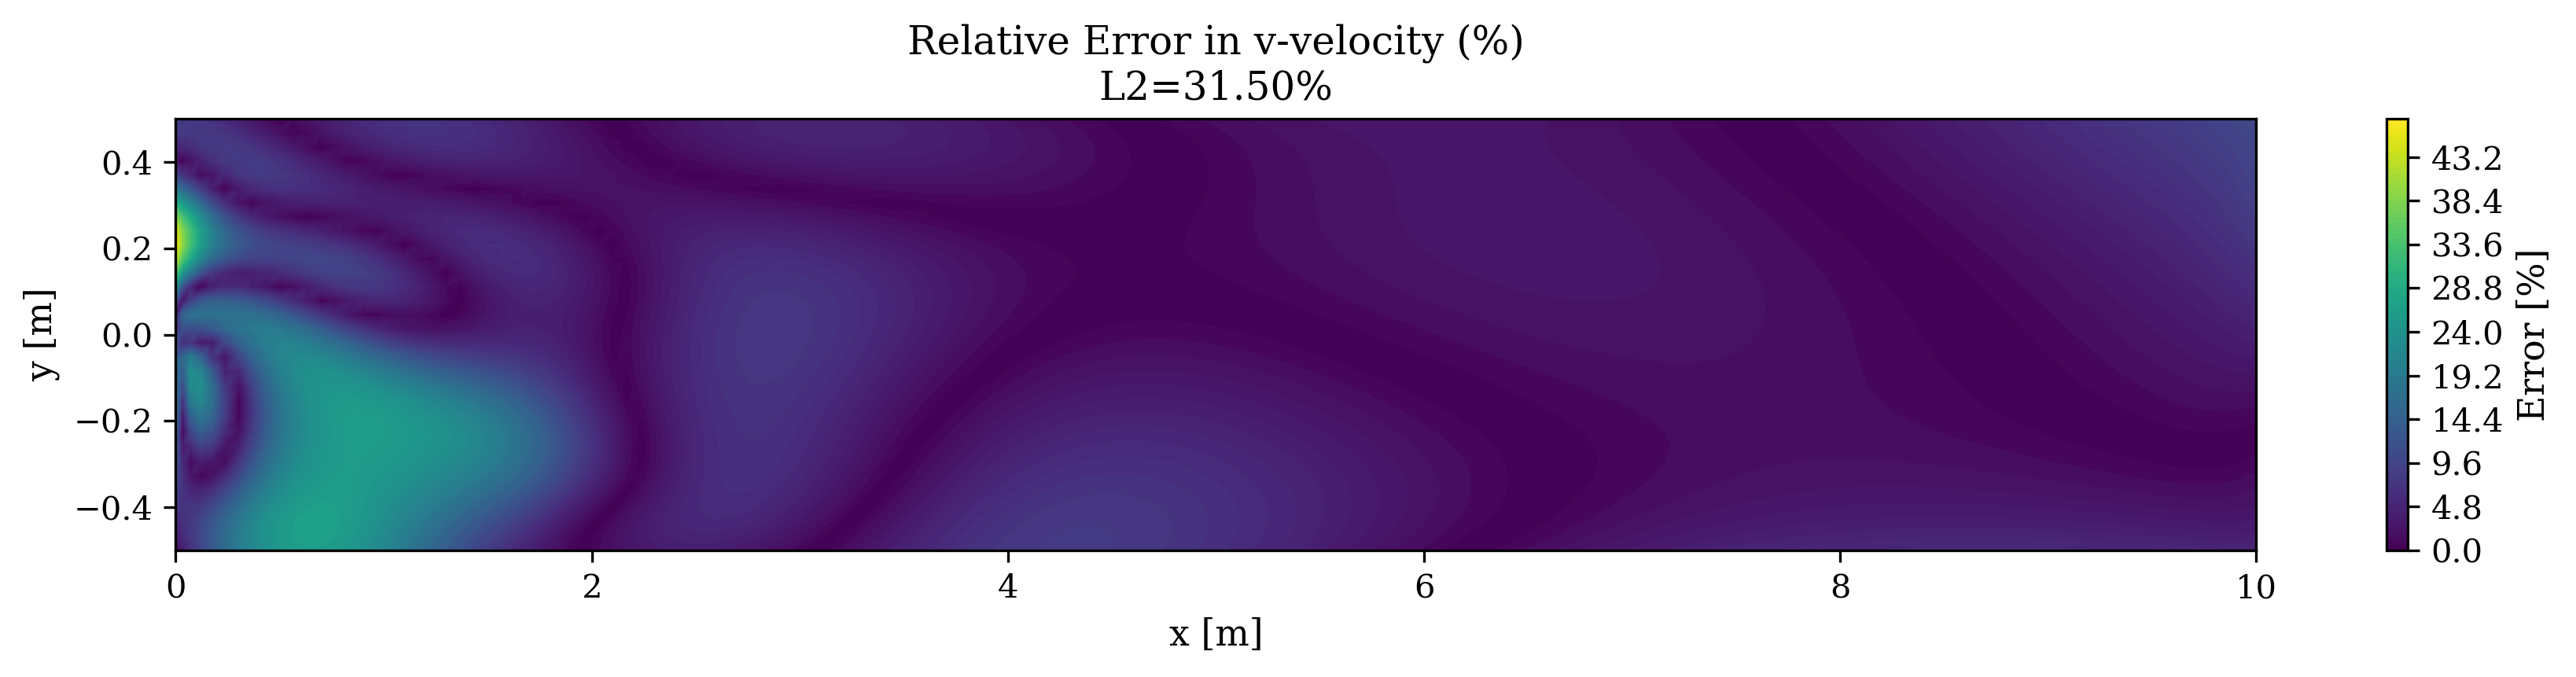

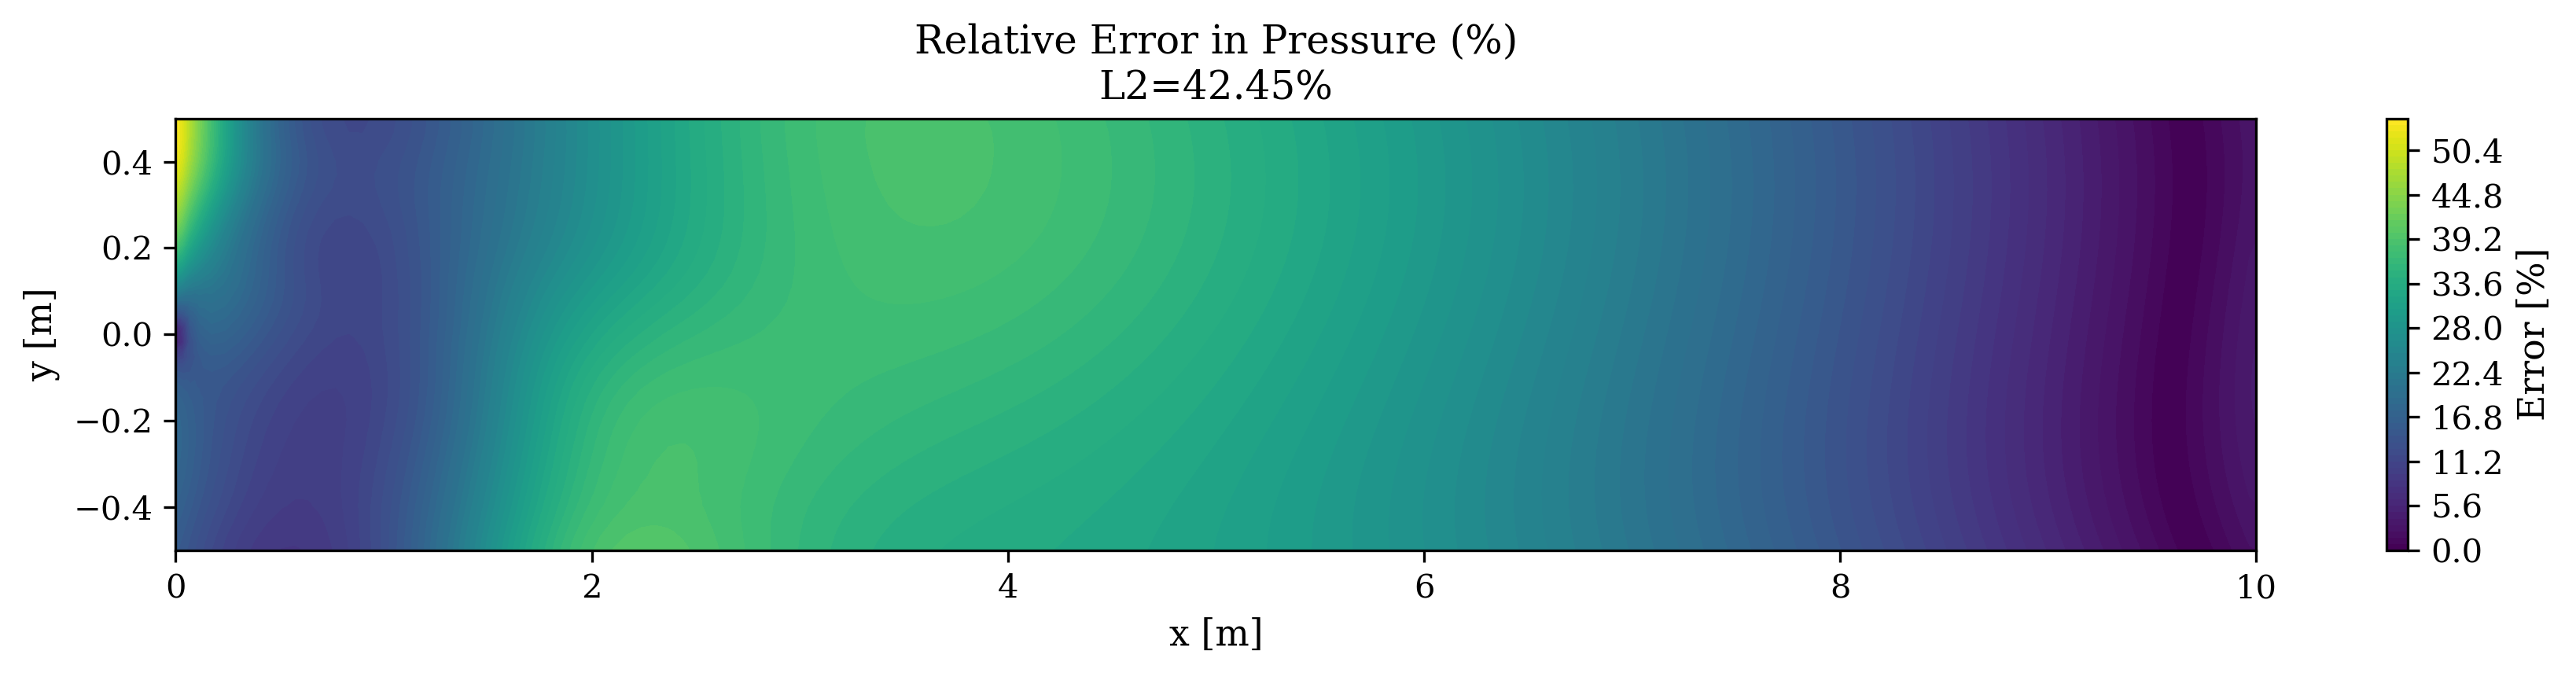

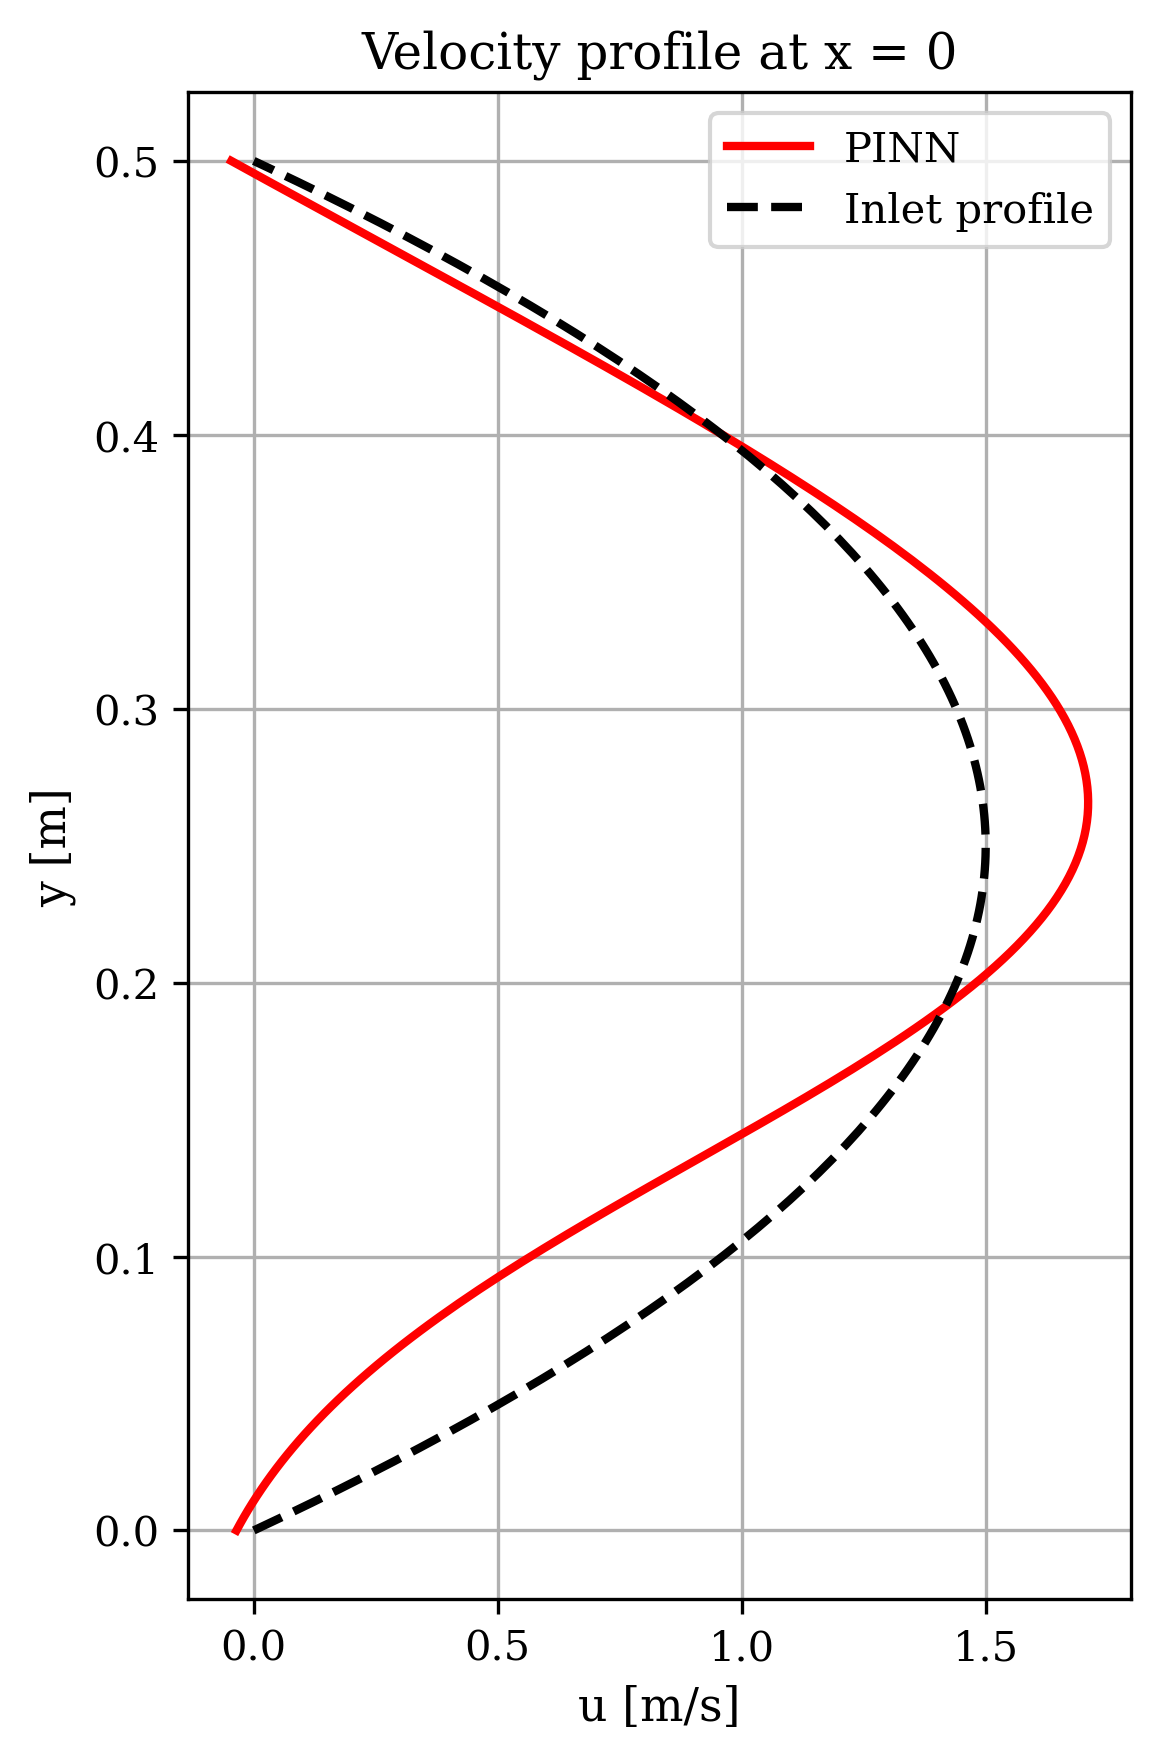

In [14]:
net = Pinns()
#net.network.load_state_dict(torch.load(os.path.join(DIRS["models"], "model_best.pth")))
net.train(num_epochs=1000)
net.plot()

In [1]:
import shutil
import os
folder_path = 'ii-PINNs-inverse-Results'
shutil.rmtree(folder_path)